# 20 – LSTM: ein Netz lernt den Normalbetrieb und findet dabei Fehler

**Zweck:** Die Kennzahlen aus Notebook 18 hat jemand ausgesucht. Ein neuronales Netz
kann aus den Stundenwerten selbst lernen, was das Verhalten einer Station ausmacht —
ohne dass vorher feststeht, worauf es ankommt, und **ohne Labels**.

**Die Idee in drei Schritten**

1. Ein LSTM liest einen Tag einer Station (24 Stunden, sechs Größen) und soll daraus
   den **nächsten Tag vorhersagen**. Dazwischen muss es den Tag durch einen Engpass
   aus **acht Zahlen** schicken — das *Embedding*.
2. Um gut vorherzusagen, muss das Netz in diese acht Zahlen packen, wie die Station
   tickt: Regelt sie sauber? Läuft nachts Wasser durch? Kühlt sie gut aus?
3. Das mittlere Embedding einer Station über einen Winter ist dann eine Beschreibung
   der Station — und darauf lernt eine **logistische Regression**, welche Stationen
   bei der Begehung einen Befund hatten.

**Vorgabe der Betreuung:** Das LSTM lernt auf den **HAST mit Begehungsdaten**. Gelernt
wird also nur aus den Tagen der begangenen Zähler, und zwar nur aus der Zeit **vor**
ihrer Begehung. Die übrigen Zähler werden mit dem fertigen Netz nur übersetzt. Zum
Vergleich läuft dasselbe Netz auch einmal auf allen Zählern (Abschnitt 5).

| Notebook | liefert |
|---|---|
| [`18_modelldaten`](18_modelldaten_labels.ipynb) | Stundenwerte mit Außentemperatur, Kennzahlen, Labels |

**Ergebnis:** `lstm_embedding.csv` (Embeddings je Zähler), `lstm_scores.csv`
(Vorhersagen aus der Prüfung), Modellgewichte in `notebooks/models/`.

## Warum ein LSTM? Der Weg dahin

Das LSTM war nicht der erste Versuch, sondern das Ergebnis vieler gescheiterter.
Die Zahlen sind AUCs gegen die Befunde der Begehungen (0,5 = Raten, 1 = perfekt),
gemessen in der lokalen Vorarbeit auf 52–53 begangenen Stationen.

| Versuch | Ventil | Dämmung | Warum es nicht gereicht hat |
|---|---|---|---|
| Unüberwachte Anomalie-Scores (Isolation Forest, LOF, PCA, K-Means-Distanz), [`02`](02_gesamtpipeline_rohdaten_bis_wartungsbenchmark.ipynb) | 0,49–0,53* | – | „ungewöhnlich“ ist nicht „defekt“; ohne Wissen über die Fehlerart kein Signal |
| Anomalie-Score gegen die ganze Flotte (robuste Kovarianz) | 0,81 | 0,45 | findet extreme Stationen, aber nur das Ventil und nicht die Dämmung |
| Regel „nachts im Sommer nie still“ | 0,87–0,91 | 0,48 | stark fürs Ventil, aber **nur im Sommer** und nur für das eine Fehlerbild |
| Rücklauf bei 0 °C (wetterbereinigt) | 0,76 | 0,24 | der Rücklauf allein sagt zu wenig, bei der Dämmung sogar verkehrt herum |
| Logistische Regression auf 9 Kennzahlen | 0,87 | 0,75 | gut, aber jemand muss die Kennzahlen kennen, und im Winter fehlt das Ventilsignal |
| **LSTM-Autoencoder** („Tag nachbilden“) | 0,88 | 0,68 | lernt das Typische eines Tages, aber zu wenig über die Station |
| **LSTM „nächsten Tag vorhersagen“** | 0,89 | 0,76 | **gewählt**: muss lernen, wie die Station auf Wetter und Vortag reagiert |
| Suche über 24 Varianten (LSTM, GRU, 1D-CNN; Größe; Kern) | 0,85–0,88 | 0,69–0,78 | die Aufgabe entscheidet, nicht der Netztyp (Abschnitt 5) |
| Embedding + Nachbarn im Leitungsgraphen (Graph-Netz) | 0,89 | 0,66 | die Nachbarn bringen nichts: die Fehler sitzen im einzelnen Haus |

\* gegen „Maßnahme ja/nein“, nicht gegen das Ventil.

**Was daraus gelernt wurde:**
- **Unüberwacht allein reicht nicht.** Wer nur nach Ungewöhnlichem sucht, findet die
  großen Abnehmer und die Messfehler, nicht die Fehler.
- **Ein großes Netz direkt auf die Labels zu trainieren, wurde gar nicht erst versucht.**
  Bei 11 Ventilfällen und über 100.000 Gewichten würde es die Fälle auswendig lernen.
- Daher die zweistufige Lösung: Das LSTM lernt **ohne Labels** aus zehntausenden Tagen,
  eine **einfache** logistische Regression nutzt erst danach die 53 Labels.

## 1 · Setup

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, LeaveOneOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
MODELLE = ROOT / "notebooks" / "models"
MODELLE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

STICHTAG = pd.Timestamp("2024-09-01")
NEU_TRAINIEREN = False      # True: Gewichte ignorieren und neu lernen
SEED = 0
torch.manual_seed(SEED)
GERAET = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, gerechnet auf: {GERAET}")

PyTorch 2.11.0+cu128, gerechnet auf: cuda


**Was macht diese Zelle?**
- Lädt PyTorch für das Netz und scikit-learn für die Prüfung.
- `NEU_TRAINIEREN = False` heißt: Liegen schon Gewichte in `notebooks/models/`, werden sie
  geladen statt neu gelernt. Der Ordner ist gitignored, beim ersten Lauf auf einem neuen
  Rechner wird also immer trainiert.
- Gerechnet wird auf der Grafikkarte, wenn es eine gibt. Ohne GPU läuft alles auch auf der
  CPU, nur langsamer.

## 2 · Daten laden und ansehen

In [2]:
stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler")
print(f"stunden: {stunden.shape[0]:,} Zeilen × {stunden.shape[1]} Spalten, {stunden['zaehler'].nunique()} Zähler")
print(f"labels:  {labels.shape[0]} begangene Zähler, kz: {kz.shape[0]} Zähler × {kz.shape[1]} Kennzahlen")
stunden.dropna().sample(5, random_state=SEED).sort_values(["zaehler", "timestamp"])

stunden: 2,128,400 Zeilen × 8 Spalten, 93 Zähler
labels:  56 begangene Zähler, kz: 91 Zähler × 16 Kennzahlen


,zaehler,timestamp,vorlauf,ruecklauf,spreizung,durchfluss,leistung,aussen
12366,53198226,2023-04-01 05:00:00,63.8,55.9,7.9,0.0,0.00,9.8
261149,68956344,2024-12-04 17:00:00,68.4,58.6,9.7,242.0,2.77,3.1
320762,68956347,2024-05-07 10:00:00,72.5,41.0,31.5,0.0,0.00,12.3
617238,68956361,2024-06-27 09:00:00,55.7,46.4,9.3,0.0,0.00,20.8
1736256,80912172,2024-12-27 23:00:00,42.7,41.5,1.1,0.0,0.00,-3.2


**Was macht diese Zelle?**
- Lädt die drei Dateien aus Notebook 18 und zeigt fünf zufällige vollständige Stundenzeilen.
  Das ist das Rohmaterial des Netzes: je Stunde Vorlauf, Rücklauf, Spreizung, Durchfluss,
  Leistung und Außentemperatur.

### Vollständige Tage als Feld

Das Netz liest Tage. Jeder vollständige Tag wird zu einer Tabelle mit 24 Zeilen
(Stunden) und 6 Spalten (Größen). Alle Tage zusammen ergeben ein dreidimensionales
Feld: Tage × 24 × 6.

In [3]:
KANAELE = ["leistung", "durchfluss", "spreizung", "vorlauf", "ruecklauf", "aussen"]
stunden = stunden.dropna(subset=KANAELE)
stunden["tag"] = stunden["timestamp"].dt.floor("D")
voll = stunden.groupby(["zaehler", "tag"])["timestamp"].transform("size") == 24
stunden = stunden[voll].sort_values(["zaehler", "timestamp"])

werte = stunden[KANAELE].to_numpy(dtype=np.float32).reshape(-1, 24, len(KANAELE))
tage = stunden[["zaehler", "tag"]].iloc[::24].reset_index(drop=True)

# Je Zähler: bis wann gilt "vor der Begehung"? Und gehört er zu den begangenen HAST?
grenze = labels["erste_begehung"].clip(upper=STICHTAG)
tage["vorher"] = tage["tag"] < tage["zaehler"].map(grenze).fillna(STICHTAG)
tage["begangen"] = tage["zaehler"].isin(labels.index)
print(f"Feld: {werte.shape[0]:,} Tage × {werte.shape[1]} Stunden × {werte.shape[2]} Größen")
pd.crosstab(tage["begangen"].map({True: "begangene HAST", False: "nie begangen"}),
            tage["vorher"].map({True: "vor der Begehung", False: "danach"}), margins=True, margins_name="Summe")

Feld: 67,840 Tage × 24 Stunden × 6 Größen


vorher,danach,vor der Begehung,Summe
begangen,,,
begangene HAST,17568,24684,42252
nie begangen,9781,15807,25588
Summe,27349,40491,67840


**Was macht diese Zelle?**
- Wirft Stunden mit fehlenden Werten weg und behält nur Tage, an denen alle 24 Stunden übrig
  bleiben.
- `reshape(-1, 24, 6)` macht aus der langen Stundentabelle das Feld: Weil die Tabelle nach
  Zähler und Zeit sortiert ist, stehen immer 24 Zeilen hintereinander, die einen Tag bilden.
- `tage` merkt sich zu jedem Eintrag im Feld Zähler und Datum, ob der Tag vor der ersten
  Begehung liegt und ob der Zähler überhaupt begangen wurde.
- Die Kreuztabelle zeigt, woraus das Netz lernen darf: **begangene HAST, vor der Begehung**.

### Skalierung

Neuronale Netze lernen schlecht, wenn eine Größe in Hunderten (Durchfluss) und die
andere in Zehnern (Temperatur) gemessen wird. Zwei Regeln:

* **Leistung und Durchfluss je Zähler**, geteilt durch das 95-%-Quantil des Zählers.
  Ein Mehrfamilienhaus und ein kleines Einfamilienhaus sollen dasselbe Verhalten auch
  gleich aussehen lassen.
* **Temperaturen und Spreizung für alle gleich** standardisiert. 65 °C Rücklauf ist in
  jedem Haus schlecht — das soll das Netz sehen.

Die Skalen kommen nur aus Tagen vor den Begehungen. Für die nie begangenen Zähler wird
ihr eigenes 95-%-Quantil genauso bestimmt, damit das fertige Netz sie übersetzen kann.

In [4]:
x = werte.copy()
vorher = tage["vorher"].to_numpy()
stunde_vorher = np.repeat(vorher, 24)          # dieselbe Markierung je Stunde (gleiche Reihenfolge wie im Feld)
teiler, mittel, streuung, skalen = {}, {}, {}, {}
for i, kanal in enumerate(KANAELE):
    if kanal in ("leistung", "durchfluss"):
        teiler[kanal] = stunden[stunde_vorher].groupby("zaehler")[kanal].quantile(0.95).clip(lower=1e-3)
        je_tag = tage["zaehler"].map(teiler[kanal]).fillna(1.0).to_numpy(dtype=np.float32)
        x[:, :, i] = werte[:, :, i] / je_tag[:, None]
        skalen[kanal] = "Wert / 95-%-Quantil des Zählers"
    else:
        mittel[kanal], streuung[kanal] = werte[vorher, :, i].mean(), werte[vorher, :, i].std()
        x[:, :, i] = (werte[:, :, i] - mittel[kanal]) / streuung[kanal]
        skalen[kanal] = f"(Wert − {mittel[kanal]:.1f}) / {streuung[kanal]:.1f}"
pd.DataFrame({"Skalierung": pd.Series(skalen),
              "Mittel danach": pd.Series(x[vorher].mean(axis=(0, 1)), index=KANAELE).round(2),
              "Streuung danach": pd.Series(x[vorher].std(axis=(0, 1)), index=KANAELE).round(2)})

,Skalierung,Mittel danach,Streuung danach
leistung,Wert / 95-%-Quantil des Zählers,0.27,0.37
durchfluss,Wert / 95-%-Quantil des Zählers,0.35,0.40
spreizung,(Wert − 15.9) / 13.6,-0.00,1.00
vorlauf,(Wert − 63.2) / 15.5,-0.00,1.00
ruecklauf,(Wert − 47.3) / 15.8,0.00,1.00
aussen,(Wert − 11.7) / 8.3,0.00,1.00


**Was macht diese Zelle?**
- Für Leistung und Durchfluss: Je Zähler wird das 95-%-Quantil aller Stundenwerte vor der
  Begehung bestimmt und jeder Wert dadurch geteilt. Typische Werte liegen danach zwischen 0 und 1.
- Für die Temperaturen: Mittelwert abziehen, durch die Streuung teilen, mit denselben zwei
  Zahlen für alle Zähler.
- Die Tabelle zeigt die Rechnung und kontrolliert das Ergebnis.

### Lernbeispiele: heute → morgen

Die Aufgabe heißt „aus heute morgen vorhersagen“. Gebraucht werden also Paare aus zwei
**aufeinanderfolgenden** vollständigen Tagen desselben Zählers. Das Netz bekommt
heute komplett und von morgen nur die Außentemperatur — die ist bekannt (Wetterbericht),
das Verhalten der Station nicht.

Für den Vergleich in Abschnitt 5 gibt es zwei weitere Varianten: dieselbe Aufgabe auf
**allen** Zählern, und die Aufgabe „**Tag nachbilden**“ (Autoencoder), bei der Ein- und
Ausgabe derselbe Tag sind. Die Funktion `beispiele()` stellt für jede Variante die
passenden Tage zusammen.

Validiert wird auf ganzen Kalenderwochen, nicht auf einzelnen Tagen: Der 14. Januar einer
Station gleicht dem 13. fast aufs Haar — läge nur er in der Validierung, wäre sie zu leicht.

In [5]:
folgetag = ((tage["zaehler"].shift(-1) == tage["zaehler"])
            & (tage["tag"].shift(-1) == tage["tag"] + pd.Timedelta(days=1))).to_numpy()


def beispiele(nur_begangene, aufgabe):
    # Eingangstage und Zieltage für eine Variante, dazu die Markierung der Validierungswochen
    erlaubt = vorher & (tage["begangen"].to_numpy() if nur_begangene else True)
    if aufgabe == "vorhersagen":
        heute = np.flatnonzero(folgetag & erlaubt & np.roll(erlaubt, -1))
        ziel_tag = heute + 1
    else:  # nachbilden: Eingang und Ziel sind derselbe Tag
        heute = np.flatnonzero(erlaubt)
        ziel_tag = heute
    woche = tage.loc[ziel_tag, "tag"].dt.to_period("W").astype(str).to_numpy()
    wochen = np.unique(woche)
    val_wochen = np.random.default_rng(SEED).choice(wochen, size=int(0.1 * len(wochen)), replace=False)
    return heute, ziel_tag, np.isin(woche, val_wochen)


VARIANTEN = {
    "begangen":    {"nur_begangene": True,  "aufgabe": "vorhersagen", "text": "nächsten Tag vorhersagen, nur begangene HAST (Hauptmodell)"},
    "alle":        {"nur_begangene": False, "aufgabe": "vorhersagen", "text": "nächsten Tag vorhersagen, alle HAST"},
    "nachbilden":  {"nur_begangene": True,  "aufgabe": "nachbilden",  "text": "Tag nachbilden (Autoencoder), nur begangene HAST"},
}
zeilen = []
for name, v in VARIANTEN.items():
    heute, ziel_tag, ist_val = beispiele(v["nur_begangene"], v["aufgabe"])
    zeilen.append({"Variante": name, "Beschreibung": v["text"], "Beispiele": len(heute),
                   "davon Validierung": int(ist_val.sum()), "Zähler": tage.loc[heute, "zaehler"].nunique()})
pd.DataFrame(zeilen).set_index("Variante")

,Beschreibung,Beispiele,davon Validierung,Zähler
Variante,,,,
begangen,"nächsten Tag vorhersagen, nur begangene HAST (...",24236,1987,54
alle,"nächsten Tag vorhersagen, alle HAST",39711,3318,90
nachbilden,"Tag nachbilden (Autoencoder), nur begangene HAST",24684,1999,54


**Was macht diese Zelle?**
- `folgetag` ist wahr, wenn der nächste Eintrag im Feld derselbe Zähler am nächsten
  Kalendertag ist. Nur dann ist es ein echtes Paar.
- `beispiele()` nimmt nur Tage vor der Begehung, beim Hauptmodell zusätzlich nur Tage der
  begangenen Zähler, und legt 10 % der Kalenderwochen als Validierung fest.
- Die Tabelle zeigt, wie viele Lernbeispiele jede Variante hat. Das Hauptmodell hat weniger
  Beispiele als „alle“, dafür nur Stationen, deren Zustand durch die Begehung bekannt ist.

## 3 · Das Netz

```
heute (24 × 6) ──► LSTM-Encoder (96) ──► 8 Zahlen = Embedding
                                              │
          Außentemperatur morgen (24 × 1) ──► LSTM-Decoder (96) ──► morgen (24 × 5)
```

Der **Encoder** liest den Tag Stunde für Stunde und fasst ihn im letzten Zustand
zusammen. Eine lineare Schicht presst das auf acht Zahlen. Der **Decoder** bekommt diese
acht Zahlen zu jeder Stunde des Zieltags, dazu die Außentemperatur dieser Stunde, und gibt
die fünf Größen aus. Beim Autoencoder ist der Zieltag derselbe Tag.

In [6]:
class LSTMEmbedding(nn.Module):
    def __init__(self, n_ein=6, n_aus=5, versteckt=96, kern=8):
        super().__init__()
        self.encoder = nn.LSTM(n_ein, versteckt, batch_first=True)
        self.zum_kern = nn.Linear(versteckt, kern)
        self.vom_kern = nn.Linear(kern, versteckt)
        self.decoder = nn.LSTM(versteckt + 1, versteckt, batch_first=True)
        self.ausgang = nn.Linear(versteckt, n_aus)

    def einbetten(self, tag):
        _, (zustand, _) = self.encoder(tag)
        return self.zum_kern(zustand[-1])

    def forward(self, tag, aussen_ziel):
        kern = self.einbetten(tag)
        je_stunde = self.vom_kern(kern).unsqueeze(1).repeat(1, aussen_ziel.shape[1], 1)
        y, _ = self.decoder(torch.cat([je_stunde, aussen_ziel], dim=2))
        return self.ausgang(y)


print(LSTMEmbedding())
print(f"{sum(p.numel() for p in LSTMEmbedding().parameters()):,} lernbare Gewichte")

LSTMEmbedding(
  (encoder): LSTM(6, 96, batch_first=True)
  (zum_kern): Linear(in_features=96, out_features=8, bias=True)
  (vom_kern): Linear(in_features=8, out_features=96, bias=True)
  (decoder): LSTM(97, 96, batch_first=True)
  (ausgang): Linear(in_features=96, out_features=5, bias=True)
)
116,941 lernbare Gewichte


**Was macht diese Zelle?**
- Baut das Netz aus fertigen PyTorch-Bausteinen: zwei `nn.LSTM` und drei `nn.Linear`.
- `einbetten()` liefert die acht Zahlen. Diese Funktion wird nach dem Training allein
  benutzt, um jeden Tag zu übersetzen.
- `forward()` ist der ganze Weg vom Eingangstag zum Zieltag und wird nur zum Lernen gebraucht.

## 4 · Training des Hauptmodells (nur begangene HAST)

Gelernt wird mit dem Adam-Optimierer und dem mittleren quadratischen Fehler. Nach jeder
Runde durch alle Trainingsbeispiele wird der Fehler auf der Validierung gemessen. Wird er
20 Runden lang nicht besser, ist Schluss (**Early Stopping**), und der beste Stand wird
behalten. Stagniert er 5 Runden, wird die Lernrate halbiert.

In [7]:
def trainieren(heute, ziel_tag, ist_val, max_runden=300, geduld=20, stapel=512):
    torch.manual_seed(SEED)
    modell = LSTMEmbedding().to(GERAET)
    opt = torch.optim.Adam(modell.parameters(), lr=3e-3)
    plan = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5, min_lr=1e-5)
    e = torch.tensor(x[heute]).to(GERAET)
    z = torch.tensor(x[ziel_tag][:, :, :5]).to(GERAET)
    a = torch.tensor(x[ziel_tag][:, :, 5:]).to(GERAET)
    lern, val = np.flatnonzero(~ist_val), torch.tensor(np.flatnonzero(ist_val), device=GERAET)
    verlauf, bester, bester_zustand, ohne_besserung = [], np.inf, None, 0
    for runde in range(max_runden):
        modell.train()
        summe = 0.0
        for teil in np.array_split(np.random.default_rng(runde).permutation(lern), max(1, len(lern) // stapel)):
            i = torch.tensor(teil, device=GERAET)
            verlust = nn.functional.mse_loss(modell(e[i], a[i]), z[i])
            opt.zero_grad()
            verlust.backward()
            opt.step()
            summe += verlust.item() * len(teil)
        modell.eval()
        with torch.no_grad():
            v = nn.functional.mse_loss(modell(e[val], a[val]), z[val]).item()
        verlauf.append({"runde": runde + 1, "training": summe / len(lern), "validierung": v})
        plan.step(v)
        if v < bester - 1e-5:
            bester, ohne_besserung = v, 0
            bester_zustand = {k: w.detach().clone() for k, w in modell.state_dict().items()}
        else:
            ohne_besserung += 1
            if ohne_besserung >= geduld:
                break
    modell.load_state_dict(bester_zustand)
    return modell, pd.DataFrame(verlauf)


def laden_oder_trainieren(name):
    datei = MODELLE / f"lstm_embedding_{name}.pt"
    v = VARIANTEN[name]
    heute, ziel_tag, ist_val = beispiele(v["nur_begangene"], v["aufgabe"])
    if datei.exists() and not NEU_TRAINIEREN:
        modell = LSTMEmbedding().to(GERAET)
        gespeichert = torch.load(datei, map_location=GERAET)
        modell.load_state_dict(gespeichert["gewichte"])
        verlauf = pd.DataFrame(gespeichert["verlauf"])
        print(f"{name:11s} Gewichte geladen aus {datei.relative_to(ROOT)}")
    else:
        start = time.time()
        modell, verlauf = trainieren(heute, ziel_tag, ist_val)
        torch.save({"gewichte": modell.state_dict(), "verlauf": verlauf.to_dict("list")}, datei)
        print(f"{name:11s} trainiert in {time.time() - start:.0f} s, gespeichert in {datei.relative_to(ROOT)}")
    modell.eval()
    return modell, verlauf, (heute, ziel_tag, ist_val)


modell, verlauf, (heute, ziel_tag, ist_val) = laden_oder_trainieren("begangen")
beste_runde = int(verlauf.loc[verlauf["validierung"].idxmin(), "runde"])
print(f"{len(verlauf)} Runden, bester Validierungsfehler {verlauf['validierung'].min():.4f} in Runde {beste_runde}")

begangen    trainiert in 11 s, gespeichert in notebooks/models/lstm_embedding_begangen.pt
92 Runden, bester Validierungsfehler 0.1772 in Runde 72


**Was macht diese Zelle?**
- `trainieren()` ist die übliche PyTorch-Schleife: Stapel von 512 Beispielen durch das Netz
  schicken, Fehler berechnen, `backward()`, `step()`. Am Ende jeder Runde wird der
  Validierungsfehler gemessen und der beste Stand gemerkt.
- `laden_oder_trainieren()` lädt gespeicherte Gewichte, wenn es sie gibt, und trainiert
  sonst. Gewichte und Lernkurve werden zusammen gespeichert, damit ein zweiter Lauf dieselbe
  Kurve zeigt, ohne neu zu lernen.

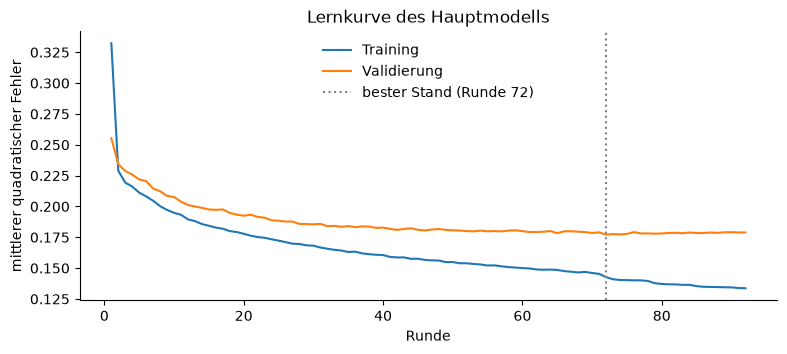

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(verlauf["runde"], verlauf["training"], label="Training")
ax.plot(verlauf["runde"], verlauf["validierung"], label="Validierung")
ax.axvline(beste_runde, color="grey", ls=":", label=f"bester Stand (Runde {beste_runde})")
ax.set_xlabel("Runde")
ax.set_ylabel("mittlerer quadratischer Fehler")
ax.set_title("Lernkurve des Hauptmodells")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Was macht diese Zelle?**
- Zeigt, wie der Fehler über die Runden sinkt. Laufen Training und Validierung weit
  auseinander, lernt das Netz die Trainingstage auswendig (Überanpassung).

**Was man sieht**

- Der Validierungsfehler fällt in den ersten 20 Runden steil und wird ab etwa Runde 40 flach. Der beste Stand liegt in Runde 72, danach bricht das Early Stopping nach 20 Runden ohne Besserung ab (Runde 92).
- Der Trainingsfehler sinkt weiter, der Validierungsfehler nicht mehr. Ab hier würde das Netz anfangen, die Trainingstage auswendig zu lernen.
- Auf der Grafikkarte dauert das rund 11 Sekunden, weil nur die begangenen HAST gelernt werden (24.236 statt 39.711 Beispiele).

Validierungsfehler je Tag: Median 0.141; gezeigt wird ein Wintertag mit 0.120


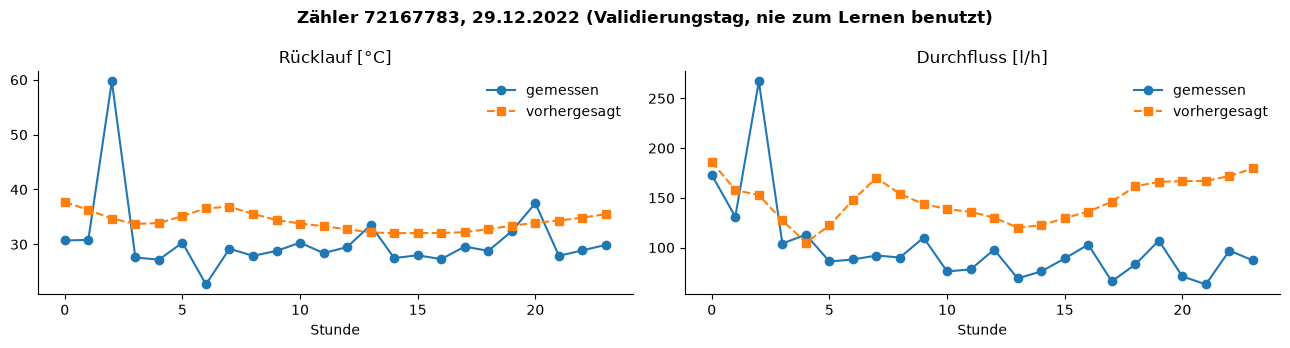

In [9]:
# Ein typischer Validierungstag im Winter: der mit dem mittleren Vorhersagefehler
val_index = np.flatnonzero(ist_val)
with torch.no_grad():
    val_vorhersage = modell(torch.tensor(x[heute[val_index]]).to(GERAET),
                            torch.tensor(x[ziel_tag[val_index]][:, :, 5:]).to(GERAET)).cpu().numpy()
fehler_je_tag = ((val_vorhersage - x[ziel_tag[val_index]][:, :, :5]) ** 2).mean(axis=(1, 2))
im_winter = tage.loc[ziel_tag[val_index], "tag"].dt.month.isin([12, 1, 2]).to_numpy()
kandidaten = np.flatnonzero(im_winter)
mitte = kandidaten[np.argsort(fehler_je_tag[kandidaten])[len(kandidaten) // 2]]
vorhersage, tag_index = val_vorhersage[mitte], ziel_tag[val_index[mitte]]
print(f"Validierungsfehler je Tag: Median {np.median(fehler_je_tag):.3f}; gezeigt wird ein Wintertag mit {fehler_je_tag[mitte]:.3f}")
zaehler, datum = tage.loc[tag_index, "zaehler"], tage.loc[tag_index, "tag"]
i_rl, i_fl = KANAELE.index("ruecklauf"), KANAELE.index("durchfluss")
rl_vorh = vorhersage[:, i_rl] * streuung["ruecklauf"] + mittel["ruecklauf"]
fl_vorh = vorhersage[:, i_fl] * teiler["durchfluss"][zaehler]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(werte[tag_index, :, i_rl], "o-", label="gemessen")
axes[0].plot(rl_vorh, "s--", label="vorhergesagt")
axes[0].set_title("Rücklauf [°C]")
axes[1].plot(werte[tag_index, :, i_fl], "o-", label="gemessen")
axes[1].plot(fl_vorh, "s--", label="vorhergesagt")
axes[1].set_title("Durchfluss [l/h]")
for ax in axes:
    ax.set_xlabel("Stunde")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Zähler {zaehler}, {datum:%d.%m.%Y} (Validierungstag, nie zum Lernen benutzt)", fontweight="bold")
fig.tight_layout()
plt.show()

**Was macht diese Zelle?**
- Sagt alle Validierungstage vorher und sucht unter den Wintertagen den mit dem **mittleren**
  Fehler — kein Glanzbeispiel und kein Ausreißer.
- Rechnet die Skalierung zurück in °C und l/h.
- Das Netz soll den groben Verlauf treffen, nicht jede Stunde: Für das Embedding zählt,
  dass es das Typische einer Station erfasst.

## 5 · Embeddings, Wiedererkennung und der Vergleich der drei Varianten

Jetzt wird nur noch der Encoder gebraucht. Jeder vollständige Tag — auch die der nie
begangenen Zähler und die nach den Begehungen — wird in seine acht Zahlen übersetzt. Je
Zähler und Zeitraum ergibt der Mittelwert über alle Tage eine Beschreibung der Station.

Die **Wiedererkennung** prüft ohne Labels, ob diese Beschreibung taugt: Liegt das
Winter-Embedding 23/24 einer Station ihrem eigenen von 22/23 am nächsten? Bei reinem
Raten träfe man bei n Stationen in 1/n der Fälle.

In [10]:
ZEITRAEUME = {"w2223": ("2022-10-01", "2023-04-01"), "w2324": ("2023-10-01", "2024-04-01"), "s2024": ("2024-06-01", "2024-09-01")}
MIN_TAGE = 30


def embeddings(modell):
    with torch.no_grad():
        kerne = torch.cat([modell.einbetten(torch.tensor(x[i:i + 4096]).to(GERAET)).cpu()
                           for i in range(0, len(x), 4096)]).numpy()
    kern_tab = pd.concat([tage[["zaehler", "tag", "vorher"]], pd.DataFrame(kerne, columns=[f"z{i}" for i in range(8)])], axis=1)
    teile = []
    for name, (von, bis) in ZEITRAEUME.items():
        t = kern_tab[(kern_tab["tag"] >= von) & (kern_tab["tag"] < bis) & kern_tab["vorher"]]
        m = t.groupby("zaehler")[[f"z{i}" for i in range(8)]].mean()
        teile.append(m[t.groupby("zaehler").size() >= MIN_TAGE].add_prefix(f"lstm_{name}_"))
    return pd.concat(teile, axis=1)


def wiedererkennung(emb):
    beide = emb[[f"lstm_w2223_z{i}" for i in range(8)] + [f"lstm_w2324_z{i}" for i in range(8)]].dropna()
    alt, neu = beide.filter(like="w2223").to_numpy(), beide.filter(like="w2324").to_numpy()
    abstand = np.linalg.norm(neu[:, None, :] - alt[None, :, :], axis=2)   # Station i (23/24) gegen Station j (22/23)
    rang = pd.Series((abstand < np.diag(abstand)[:, None]).sum(axis=1) + 1, index=beide.index)
    return rang                                                          # 1 = die eigene Station ist die nächste


embedding = embeddings(modell)
rang = wiedererkennung(embedding)
print(f"Embeddings für {len(embedding)} Zähler; je Zeitraum vorhanden: "
      + ", ".join(f"{n} {embedding[f'lstm_{n}_z0'].notna().sum()}" for n in ZEITRAEUME))
gruppe = rang.index.isin(labels.index)
print(f"Wiedererkennung über zwei Winter: {(rang == 1).mean():.0%} von {len(rang)} Stationen (Zufall {1 / len(rang):.0%})")
print(f"  begangene HAST (im Training):  {(rang[gruppe] == 1).mean():.0%} von {gruppe.sum()}")
print(f"  nie begangene (nie gesehen):    {(rang[~gruppe] == 1).mean():.0%} von {(~gruppe).sum()}")
embedding.round(2).head()

Embeddings für 90 Zähler; je Zeitraum vorhanden: w2223 41, w2324 87, s2024 82


Wiedererkennung über zwei Winter: 83% von 41 Stationen (Zufall 2%)
  begangene HAST (im Training):  87% von 23
  nie begangene (nie gesehen):    78% von 18


,lstm_w2223_z0,lstm_w2223_z1,lstm_w2223_z2,lstm_w2223_z3,lstm_w2223_z4,lstm_w2223_z5,lstm_w2223_z6,lstm_w2223_z7,lstm_w2324_z0,lstm_w2324_z1,lstm_w2324_z2,lstm_w2324_z3,lstm_w2324_z4,lstm_w2324_z5,lstm_w2324_z6,lstm_w2324_z7,lstm_s2024_z0,lstm_s2024_z1,lstm_s2024_z2,lstm_s2024_z3,lstm_s2024_z4,lstm_s2024_z5,lstm_s2024_z6,lstm_s2024_z7
zaehler,,,,,,,,,,,,,,,,,,,,,,,,
53198226,-0.37,0.15,-0.29,0.32,-0.28,0.14,-0.01,-0.91,-0.03,-0.16,-0.16,0.40,-0.34,0.22,-0.24,-1.12,-0.43,0.54,-0.30,-0.43,0.44,-0.04,0.20,-0.67
58177363,-0.12,-0.09,0.16,0.62,-0.55,0.16,-0.22,-0.79,0.04,-0.03,0.17,0.55,-0.52,0.14,-0.08,-0.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58177384,-0.26,-0.01,-0.75,0.04,0.23,0.03,-0.79,-0.91,-0.06,-0.04,-0.32,-0.21,-0.25,-0.01,-0.32,-0.78,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
61620222,-0.22,0.07,-0.03,0.48,-0.09,-0.12,0.13,0.07,-0.08,0.03,0.11,0.48,-0.27,-0.15,0.20,0.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65273846,0.40,-0.66,1.12,0.37,-1.12,-0.30,-0.10,-0.26,0.33,-0.49,1.20,0.18,-1.08,-0.12,0.17,0.10,0.08,0.42,0.83,-0.17,-0.70,0.18,0.51,1.13


**Was macht diese Zelle?**
- `embeddings()` übersetzt alle Tage in Stapeln von 4096 mit `modell.einbetten()` und bildet je
  Zähler den Mittelwert über drei Zeiträume (Winter 22/23, Winter 23/24, Sommer 2024), jeweils
  nur vor der Begehung und nur, wenn es mindestens 30 Tage sind.
- `wiedererkennung()` rechnet für jede Station den Abstand ihres 23/24-Embeddings zu allen
  22/23-Embeddings und zählt, wie viele fremde Stationen näher liegen als die eigene.
- Getrennt ausgewiesen: Stationen, die das Netz beim Lernen gesehen hat, und nie begangene,
  die es **nie** gesehen hat. Für sie ist die Wiedererkennung ein echter Test.

**Ergebnis**

- **83 %** der 41 Stationen mit zwei Wintern werden wiedererkannt: Ihr Embedding 23/24 liegt dem eigenen von 22/23 näher als jedem fremden. Zufall wären 2 %.
- **Auch die nie begangenen Stationen werden meist erkannt (78 % von 18, gegen 87 % von 23 bei den begangenen)**, obwohl das Netz keinen einzigen ihrer Tage beim Lernen gesehen hat. Der Abstand entspricht etwa zwei Stationen. Das Netz hat also nicht die begangenen Stationen auswendig gelernt, sondern allgemein, wie eine Station sich verhält.
- Damit ist die Vorgabe der Betreuung kein Nachteil: Das Netz, das nur auf den begangenen HAST lernt, beschreibt auch alle anderen.

### Die Vorgabe und die Alternativen im direkten Vergleich

Jetzt dieselbe Rechnung für die beiden anderen Varianten. Damit die Zahlen vergleichbar
sind, wird jede Variante gleich geprüft: Wiedererkennung ohne Labels, und die verschachtelte
Fehlererkennung aus Abschnitt 6 mit den Embeddings allein.

In [11]:
def verschachtelt(X, y, gruppen=None):
    # Vorhersage je Station aus einem Modell, das diese Station nie gesehen hat
    pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             LogisticRegression(class_weight="balanced", max_iter=5000))
    suche = GridSearchCV(pipeline, {"logisticregression__C": [0.03, 0.1, 0.3, 1.0]},
                         cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc")
    aussen = LeaveOneOut() if gruppen is None else LeaveOneGroupOut()
    return cross_val_predict(suche, X, y, cv=aussen, groups=gruppen, method="predict_proba", n_jobs=-1)[:, 1]


def auc_mit_intervall(y, score, n=2000):
    y, score = np.asarray(y), np.asarray(score)
    rng = np.random.default_rng(SEED)
    ziehungen = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            ziehungen.append(roc_auc_score(y[i], score[i]))
    return roc_auc_score(y, score), np.quantile(ziehungen, 0.025), np.quantile(ziehungen, 0.975)


def precision_at_k(y, score, k=10):
    return np.asarray(y)[np.argsort(-np.asarray(score))[:k]].mean()


LSTM_WINTER = [f"lstm_w2324_z{i}" for i in range(8)]
LSTM_SOMMER = [f"lstm_s2024_z{i}" for i in range(8)]
alle_embeddings = {"begangen": embedding}
for name in ("alle", "nachbilden"):
    m, verl, _ = laden_oder_trainieren(name)
    alle_embeddings[name] = embeddings(m)

# gleiche Prüfbasis für alle Varianten: begangene Zähler mit Winter-Embedding und Sommerwerten in jeder Variante
basis_index = labels.index.intersection(kz.dropna(subset=["sommer_durchlauf_anteil"]).index)
for emb in alle_embeddings.values():
    basis_index = basis_index.intersection(emb.dropna(subset=LSTM_WINTER).index)

zeilen = []
for name, emb in alle_embeddings.items():
    r = wiedererkennung(emb)
    zeile = {"Variante": name, "Beschreibung": VARIANTEN[name]["text"], "Wiedererkennung": (r == 1).mean()}
    for ziel in ("ventil", "daemmung"):
        y = labels.loc[basis_index, ziel].astype(int).to_numpy()
        for satz, spalten in (("Winter", LSTM_WINTER), ("Winter+Sommer", LSTM_WINTER + LSTM_SOMMER)):
            zeile[f"{ziel} ({satz})"] = roc_auc_score(y, verschachtelt(emb.loc[basis_index, spalten], y))
    zeilen.append(zeile)
varianten_vergleich = pd.DataFrame(zeilen).set_index("Variante")
print(f"Prüfbasis: {len(basis_index)} begangene Zähler, gleich für alle drei Varianten")
varianten_vergleich.round(2)

alle        trainiert in 15 s, gespeichert in notebooks/models/lstm_embedding_alle.pt


nachbilden  trainiert in 17 s, gespeichert in notebooks/models/lstm_embedding_nachbilden.pt


Prüfbasis: 53 begangene Zähler, gleich für alle drei Varianten


,Beschreibung,Wiedererkennung,ventil (Winter),ventil (Winter+Sommer),daemmung (Winter),daemmung (Winter+Sommer)
Variante,,,,,,
begangen,"nächsten Tag vorhersagen, nur begangene HAST (...",0.83,0.83,0.84,0.71,0.72
alle,"nächsten Tag vorhersagen, alle HAST",0.88,0.85,0.87,0.72,0.67
nachbilden,"Tag nachbilden (Autoencoder), nur begangene HAST",0.73,0.81,0.84,0.69,0.75


**Was macht diese Zelle?**
- Definiert die Prüfwerkzeuge, die auch in Abschnitt 6 gebraucht werden: `verschachtelt()`
  (verschachtelte Kreuzvalidierung), `auc_mit_intervall()` und `precision_at_k()`.
- Lädt oder trainiert die beiden Vergleichsvarianten, übersetzt alle Tage und prüft jede
  Variante gleich: Wiedererkennung ohne Labels, AUC für Ventil und Dämmung aus den
  Embeddings allein, einmal nur Winter, einmal Winter und Sommer.

**Ergebnis**

| | Wiedererkennung | Ventil (Winter) | Ventil (W+S) | Dämmung (Winter) | Dämmung (W+S) |
|---|---|---|---|---|---|
| **Vorhersagen, nur begangene HAST** (Vorgabe) | 0,83 | 0,83 | 0,84 | 0,71 | 0,72 |
| Vorhersagen, alle HAST | 0,88 | 0,85 | 0,87 | 0,72 | 0,67 |
| Tag nachbilden (Autoencoder) | **0,73** | 0,81 | 0,84 | 0,69 | 0,75 |

- **Bei den AUCs liegen alle drei Varianten im selben Bereich.** Die Unterschiede von 0,01 bis 0,08 sind kleiner als die Unsicherheit bei 11 Ventil- und 22 Dämmungsfällen (die Intervalle sind jeweils rund ±0,15 breit). Nach den Befunden lässt sich zwischen ihnen nicht entscheiden, und das soll man auch nicht: Wer die Variante nach der besten AUC wählt, passt sie den Befunden an.
- **Die Wiedererkennung entscheidet, und sie spricht gegen den Autoencoder:** 0,73 gegen 0,83–0,88. Ein Netz, das nur den Tag nachbildet, beschreibt den einzelnen Tag gut, die Station aber schlechter. Das ist derselbe Befund wie in der lokalen Suche über 24 Varianten (0,74 gegen 0,87) und der Grund für die Aufgabe „nächsten Tag vorhersagen“.
- **Die Vorgabe „nur begangene HAST“ kostet nichts Messbares:** etwas tiefere Wiedererkennung (0,83 gegen 0,88, das sind zwei der 41 Stationen) mit rund 40 % weniger Lernbeispielen. Beim Ventil liegt sie im Winter 0,02 und mit Winter und Sommer 0,03 tiefer, bei der Dämmung mit Winter und Sommer 0,05 höher. Das ist Rauschen.

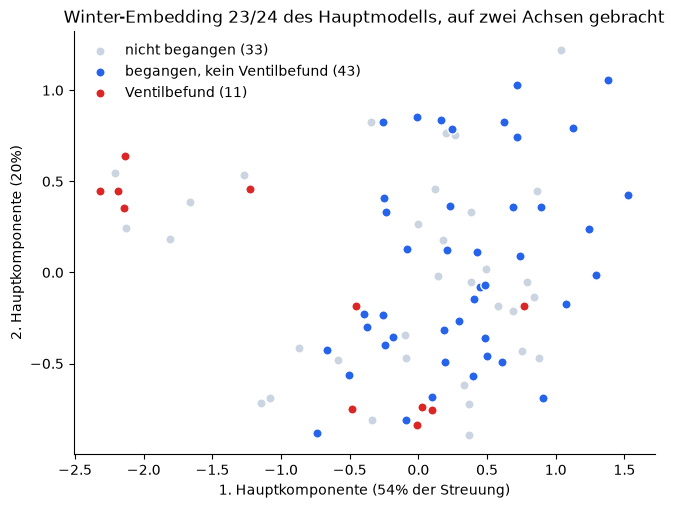

In [12]:
w = embedding.filter(like="lstm_w2324_").dropna()
pca = PCA(n_components=2).fit(w)
punkte = pd.DataFrame(pca.transform(w), index=w.index, columns=["pc1", "pc2"]).join(labels["ventil"])
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for wert, farbe, name in ((np.nan, "#CBD5E1", "nicht begangen"), (False, "#2563EB", "begangen, kein Ventilbefund"), (True, "#DC2626", "Ventilbefund")):
    teil = punkte[punkte["ventil"].isna()] if wert is np.nan else punkte[punkte["ventil"] == wert]
    ax.scatter(teil["pc1"], teil["pc2"], color=farbe, s=45, label=f"{name} ({len(teil)})", edgecolor="white")
ax.set_xlabel(f"1. Hauptkomponente ({pca.explained_variance_ratio_[0]:.0%} der Streuung)")
ax.set_ylabel(f"2. Hauptkomponente ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Winter-Embedding 23/24 des Hauptmodells, auf zwei Achsen gebracht")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Was macht diese Zelle?**
- Acht Zahlen kann man nicht zeichnen. Die Hauptkomponentenanalyse (PCA) sucht die zwei
  Richtungen, in denen die Stationen am stärksten streuen, und zeigt die Stationen darin.
- Gefärbt nach dem Ventilbefund. Das Netz hat diese Farben nie gesehen.

**Was man sieht**

- Links (1. Hauptkomponente unter −1) sitzt wieder eine eigene Gruppe: **5 der 11 Ventilfälle**, **keine einzige** begangene Station ohne Befund und **7 nie begangene** Stationen (grau). Diese sieben sind die ersten Kandidaten, Notebook 22 rechnet das mit einem Modell nach.
- Die übrigen 6 Ventilfälle liegen in der Mitte zwischen den anderen. Für sie braucht es mehr als zwei Achsen.
- Die beiden Achsen fassen 74 % der Streuung der acht Zahlen.

## 6 · Fehlererkennung: Welche Station hatte bei der Begehung einen Befund?

Jetzt kommen die Labels, mit dem Hauptmodell. Auf den Embeddings lernt eine
**logistische Regression**, ob eine Station einen Ventil- bzw. Dämmungsbefund hatte.
Damit die Prüfung ehrlich ist, gilt:

* **Verschachtelte Kreuzvalidierung.** Außen wird jede Station einmal ausgelassen
  (Leave-one-out), gelernt wird auf den übrigen. Innen wählt eine 4-fache
  Kreuzvalidierung nur auf diesen übrigen Stationen die Regularisierung `C`. Die
  ausgelassene Station sieht weder das Modell noch die Wahl von `C`.
* **AUC mit Unsicherheit.** Die AUC ist die Wahrscheinlichkeit, dass eine zufällige
  Station mit Befund vor einer zufälligen ohne Befund eingeordnet wird (0,5 = Raten,
  1 = perfekt). Das Intervall kommt aus 2000 Bootstrap-Ziehungen der Stationen.
* **Precision@10:** Wie viele der zehn am höchsten eingestuften Stationen hatten
  wirklich einen Befund? Das ist die Frage aus der Praxis: Welche zehn begehe ich zuerst?

Ein Punkt zur Vorgabe „Training auf den begangenen HAST“: Das Netz hat beim Lernen die
Tage der Stationen gesehen, die hier geprüft werden, aber **nie ihre Labels** und nie Tage
nach ihrer Begehung. Die Labels kommen erst in der Regression vor, und die ist verschachtelt
geprüft.

In [13]:
KENNZAHLEN = [c for c in kz.columns if not c.startswith("stunden_") and c != "auslastung_vertrag"]
WINTER_KZ = [c for c in KENNZAHLEN if c.startswith("winter_") or c in ("auslastung", "anteil_volumenstrom", "streubreite_betriebspunkte", "ruecklauf_lastgewichtet")]

tabelle = labels[["ventil", "daemmung", "strasse_gruppe"]].join(kz).join(embedding)
basis = tabelle.dropna(subset=LSTM_WINTER + ["sommer_durchlauf_anteil"])
print(f"Prüfbasis: {len(basis)} begangene Zähler mit Winter-Embedding und Sommerwerten "
      f"(Ventil {int(basis['ventil'].sum())}, Dämmung {int(basis['daemmung'].sum())})")
print(f"Ausgeschlossen: {len(labels) - len(basis)} begangene Zähler ohne genug Winter- oder Sommertage")

VERFAHREN = {
    "Kennzahlen (alle)": KENNZAHLEN,
    "LSTM Winter + Sommer": LSTM_WINTER + LSTM_SOMMER,
    "Kennzahlen + LSTM": KENNZAHLEN + LSTM_WINTER + LSTM_SOMMER,
    "nur Winter: Kennzahlen": WINTER_KZ,
    "nur Winter: LSTM": LSTM_WINTER,
    "nur Winter: Kennzahlen + LSTM": WINTER_KZ + LSTM_WINTER,
}
scores = {}
for ziel in ("ventil", "daemmung"):
    y = basis[ziel].astype(int).to_numpy()
    scores[(ziel, "Sommernacht-Regel (ohne Lernen)")] = basis["sommer_durchlauf_anteil"].to_numpy()
    for name, spalten in VERFAHREN.items():
        scores[(ziel, name)] = verschachtelt(basis[spalten], y)

zeilen = []
for (ziel, name), s in scores.items():
    y = basis[ziel].astype(int).to_numpy()
    auc, unten, oben = auc_mit_intervall(y, s)
    zeilen.append({"Ziel": ziel, "Verfahren": name, "AUC": auc, "unten": unten, "oben": oben, "P@10": precision_at_k(y, s)})
ergebnis = pd.DataFrame(zeilen)
ergebnis.round(2)

Prüfbasis: 53 begangene Zähler mit Winter-Embedding und Sommerwerten (Ventil 11, Dämmung 22)
Ausgeschlossen: 3 begangene Zähler ohne genug Winter- oder Sommertage


,Ziel,Verfahren,AUC,unten,oben,P@10
0,ventil,Sommernacht-Regel (ohne Lernen),0.85,0.68,0.98,0.7
1,ventil,Kennzahlen (alle),0.79,0.57,0.97,0.6
2,ventil,LSTM Winter + Sommer,0.84,0.70,0.94,0.5
3,ventil,Kennzahlen + LSTM,0.89,0.78,0.97,0.7
4,ventil,nur Winter: Kennzahlen,0.68,0.44,0.89,0.5
5,ventil,nur Winter: LSTM,0.83,0.68,0.95,0.5
6,ventil,nur Winter: Kennzahlen + LSTM,0.79,0.61,0.94,0.6
7,daemmung,Sommernacht-Regel (ohne Lernen),0.57,0.40,0.73,0.6
8,daemmung,Kennzahlen (alle),0.69,0.53,0.84,0.9
9,daemmung,LSTM Winter + Sommer,0.72,0.57,0.85,0.7


**Was macht diese Zelle?**
- Legt die Merkmalsgruppen fest: die Kennzahlen aus Notebook 18, die LSTM-Embeddings aus
  Winter und Sommer, beides zusammen, und drei Varianten **nur mit Winterdaten**.
- Die Prüfbasis ist für alle Verfahren gleich: begangene Zähler mit Winter-Embedding und
  Sommerwerten. Sonst wären die AUCs nicht vergleichbar.
- Die **Sommernacht-Regel** ist die Messlatte ohne Lernen: Stationen werden nur nach dem
  Anteil der Sommernächte mit Durchfluss sortiert.
- `auslastung_vertrag` bleibt hier draußen. Sie ist nur für begangene Zähler bekannt und
  gehört zur Überdimensionierung (Notebook 22).

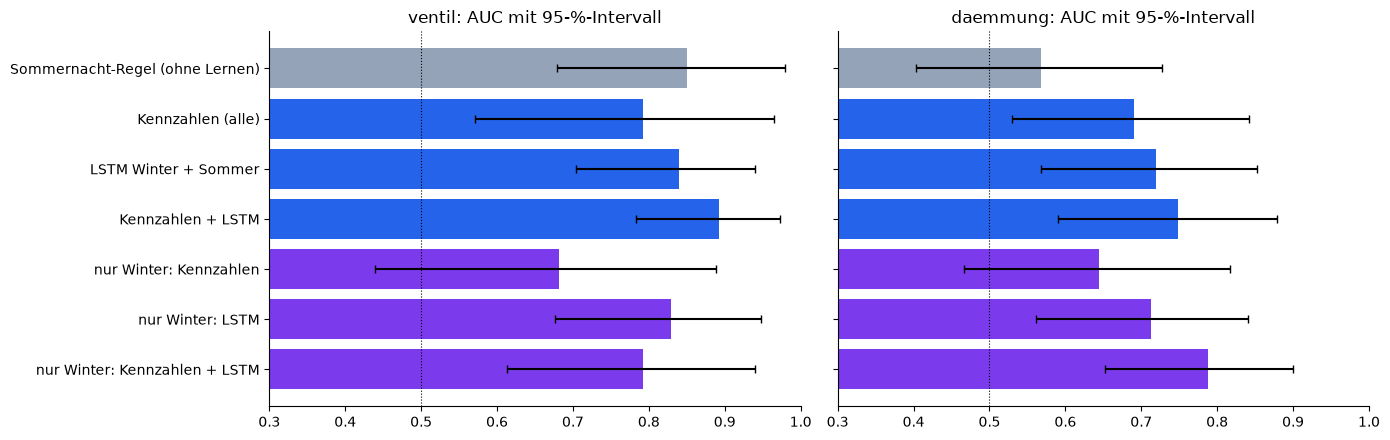

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ax, ziel in zip(axes, ("ventil", "daemmung")):
    t = ergebnis[ergebnis["Ziel"] == ziel].reset_index(drop=True)
    farben = ["#94A3B8" if "Regel" in v else "#7C3AED" if v.startswith("nur Winter") else "#2563EB" for v in t["Verfahren"]]
    ax.barh(t["Verfahren"], t["AUC"], xerr=[t["AUC"] - t["unten"], t["oben"] - t["AUC"]], color=farben, capsize=3)
    ax.axvline(0.5, color="black", lw=0.8, ls=":")
    ax.set_xlim(0.3, 1.0)
    ax.invert_yaxis()
    ax.set_title(f"{ziel}: AUC mit 95-%-Intervall")
    ax.spines[["top", "right"]].set_visible(False)
axes[1].set_yticklabels([])
fig.tight_layout()
plt.show()

**Was macht diese Zelle?**
- Zeigt die AUC je Verfahren mit dem Bootstrap-Intervall. Grau: die Regel ohne Lernen,
  blau: mit Sommerdaten, violett: nur Winterdaten. Die gepunktete Linie ist Raten.

**Ergebnis** (Hauptmodell: nur begangene HAST)

**Ventil** (11 von 53, Basisrate 21 %)

- **Mit Sommerdaten ist das Ventil leicht:** Die Regel ohne Lernen kommt auf 0,85, Kennzahlen und LSTM zusammen auf **0,89** [0,78; 0,97].
- **Nur mit Winterdaten:** Kennzahlen 0,68, LSTM **0,83**, beides 0,79. Das LSTM liegt vorne, aber mit breitem Intervall (0,68 bis 0,95).

**Dämmung** (22 von 53, Basisrate 42 %)

- Die Sommernacht-Regel sagt über Dämmung nichts (0,57). Das passt, sie misst ja das Ventil.
- Kennzahlen 0,69, LSTM 0,72, beides **0,75**. Nur mit Winterdaten kommen Kennzahlen und LSTM zusammen sogar auf **0,79**. Unter den zehn höchsten Stationen sind mit Kennzahlen 9 mit Dämmungsbefund (Zufall: 4).

### Ist der Unterschied belegt?

Zwei AUCs mit überlappenden Intervallen können trotzdem verschieden sein, weil beide
auf **denselben** Stationen gemessen werden. Richtig ist der **gepaarte** Vergleich:
In jeder Bootstrap-Ziehung werden beide Verfahren auf derselben Stichprobe bewertet
und die Differenz gemerkt. Schließt das Intervall der Differenz die 0 aus, ist der
Unterschied belegt.

In [15]:
def auc_differenz(y, a, b, n=2000):
    rng = np.random.default_rng(SEED)
    differenzen = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            differenzen.append(roc_auc_score(y[i], a[i]) - roc_auc_score(y[i], b[i]))
    return roc_auc_score(y, a) - roc_auc_score(y, b), np.quantile(differenzen, 0.025), np.quantile(differenzen, 0.975)


VERGLEICHE = [
    ("ventil", "nur Winter: LSTM", "nur Winter: Kennzahlen"),
    ("ventil", "nur Winter: LSTM", "Sommernacht-Regel (ohne Lernen)"),
    ("ventil", "Kennzahlen + LSTM", "Sommernacht-Regel (ohne Lernen)"),
    ("ventil", "Kennzahlen + LSTM", "Kennzahlen (alle)"),
    ("daemmung", "Kennzahlen + LSTM", "Kennzahlen (alle)"),
    ("daemmung", "nur Winter: LSTM", "nur Winter: Kennzahlen"),
]
zeilen = []
for ziel, a, b in VERGLEICHE:
    y = basis[ziel].astype(int).to_numpy()
    d, unten, oben = auc_differenz(y, scores[(ziel, a)], scores[(ziel, b)])
    zeilen.append({"Ziel": ziel, "Verfahren": a, "gegen": b, "Differenz": d, "unten": unten, "oben": oben,
                   "belegt": "ja" if unten > 0 or oben < 0 else "nein"})
pd.DataFrame(zeilen).round(2)

,Ziel,Verfahren,gegen,Differenz,unten,oben,belegt
0,ventil,nur Winter: LSTM,nur Winter: Kennzahlen,0.15,0.02,0.32,ja
1,ventil,nur Winter: LSTM,Sommernacht-Regel (ohne Lernen),-0.02,-0.15,0.13,nein
2,ventil,Kennzahlen + LSTM,Sommernacht-Regel (ohne Lernen),0.04,-0.04,0.15,nein
3,ventil,Kennzahlen + LSTM,Kennzahlen (alle),0.10,-0.02,0.25,nein
4,daemmung,Kennzahlen + LSTM,Kennzahlen (alle),0.06,-0.07,0.21,nein
5,daemmung,nur Winter: LSTM,nur Winter: Kennzahlen,0.07,-0.10,0.23,nein


**Was macht diese Zelle?**
- `auc_differenz()` zieht 2000-mal eine Stichprobe der Stationen und rechnet in jeder
  Ziehung die AUC beider Verfahren auf genau denselben Stationen.
- Die Tabelle zeigt die Differenz mit 95-%-Intervall und ob sie die 0 ausschließt.

**Ergebnis**

- **Ein Unterschied ist belegt: im Winter beim Ventil, LSTM gegen Kennzahlen** (+0,15, Intervall +0,02 bis +0,32). Alle anderen sind es nicht.
- **Die Richtung ist überall dieselbe:** Das LSTM liegt vor den Kennzahlen, beim Ventil mit allen Daten um +0,10, bei der Dämmung um +0,06 bis +0,07. Das ist nicht abgesichert.
- Gegen die Sommernacht-Regel ist das LSTM mit Sommerdaten gleichauf (+0,04). Wenn man den Sommer abwarten kann, reicht die einfache Regel.
- **Wie empfindlich der Wintervorsprung ist:** In der vorigen Fassung dieses Notebooks (Datenbasis mit 96 Zählern, andere Validierungswochen, eigenes Training) lag er bei +0,11 [−0,02; +0,28] und war nicht belegt. In der ersten Fassung mit dem Netz auf allen HAST war er belegt (+0,18 [0,01; 0,38]). Ob die untere Grenze knapp über oder unter 0 liegt, hängt bei 11 Fällen schon am Zufall des Trainings. Abschnitt „Ein fragliches Label“ zeigt, woran es vor allem hängt.

In [16]:
# Von Hand nachgerechnet: die AUC ist der Anteil der Paare (Befund, kein Befund),
# in denen die Station mit Befund den höheren Score hat (Gleichstand zählt halb).
y = basis["ventil"].astype(int).to_numpy()
s = scores[("ventil", "nur Winter: LSTM")]
pos, neg = s[y == 1], s[y == 0]
paare = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()
print(f"{len(pos)} × {len(neg)} = {len(pos) * len(neg)} Paare, davon richtig herum: {paare:.3f}")
assert np.isclose(paare, roc_auc_score(y, s))
print("stimmt mit roc_auc_score überein")

# Und noch einmal mit ganzen Straßen statt einzelnen Stationen ausgelassen
gruppen = basis["strasse_gruppe"].to_numpy()
for ziel, name in (("ventil", "nur Winter: LSTM"), ("ventil", "Kennzahlen + LSTM"), ("daemmung", "Kennzahlen + LSTM")):
    yz = basis[ziel].astype(int).to_numpy()
    auc, unten, oben = auc_mit_intervall(yz, verschachtelt(basis[VERFAHREN[name]], yz, gruppen))
    print(f"Straßen ausgelassen – {ziel:8s} {name:28s} AUC {auc:.2f} [{unten:.2f}; {oben:.2f}]")

11 × 42 = 462 Paare, davon richtig herum: 0.829
stimmt mit roc_auc_score überein


Straßen ausgelassen – ventil   nur Winter: LSTM             AUC 0.87 [0.74; 0.97]


Straßen ausgelassen – ventil   Kennzahlen + LSTM            AUC 0.83 [0.66; 0.94]


Straßen ausgelassen – daemmung Kennzahlen + LSTM            AUC 0.82 [0.69; 0.92]


**Was macht diese Zelle?**
- Rechnet eine AUC ohne scikit-learn nach: über alle Paare aus einer Station mit und einer
  ohne Befund zählen, wie oft die mit Befund vorne liegt.
- Wiederholt drei Prüfungen so, dass immer eine **ganze Straße** ausgelassen wird. Begangen
  wurde Straße für Straße, und Nachbarhäuser ähneln sich. Bleibt die AUC ähnlich hoch,
  hat das Modell nicht nur Nachbarn wiedererkannt.

**Ergebnis**

- Die AUC von Hand über die 462 Paare stimmt mit `roc_auc_score` überein (0,829).
- **Ganze Straßen auslassen ändert kaum etwas:** Ventil im Winter 0,87, Ventil mit allen Daten 0,83, Dämmung 0,82. Das Modell erkennt also nicht nur Nachbarhäuser wieder, deren Straße schon im Training war.

### Ein fragliches Label: wie viel hängt daran?

Die Freitext-Kodierung (`src/befundcodes.py`) zählt bei einem Zähler „Regelventil geölt und
Funktion überprüft“ als Ventilbefund. Das beschreibt eher Wartung als einen Defekt, und die
Station zeigt im Sommer auch kein Ventilbild. Ob das Label bleibt, ist eine Entscheidung
fürs Team. Hier wird nur gezeigt, **wie viel** daran hängt: dieselbe Prüfung einmal mit
und einmal ohne diesen Zähler. Das Label selbst wird nicht verändert.

In [17]:
FRAGLICH = 80912189
ohne = basis.drop(index=FRAGLICH, errors="ignore")
zeilen = []
for name in ("nur Winter: LSTM", "Kennzahlen + LSTM", "nur Winter: Kennzahlen"):
    for daten, fassung in ((basis, "mit dem Zähler (Team-Label)"), (ohne, "ohne den Zähler")):
        y = daten["ventil"].astype(int).to_numpy()
        auc, unten, oben = auc_mit_intervall(y, verschachtelt(daten[VERFAHREN[name]], y))
        zeilen.append({"Verfahren": name, "Fassung": fassung, "Stationen": len(daten), "Ventilfälle": int(y.sum()),
                       "AUC": auc, "unten": unten, "oben": oben})
print(f"Zähler {FRAGLICH}: Ventil-Label = {bool(labels.loc[FRAGLICH, 'ventil'])}, "
      f"Sommer-Durchlaufanteil {kz.loc[FRAGLICH, 'sommer_durchlauf_anteil']:.2f}, Nachtdurchfluss {kz.loc[FRAGLICH, 'sommer_nachtfluss_lph']:.0f} l/h")
fassungen = pd.DataFrame(zeilen)

# Der gepaarte Vergleich aus Abschnitt 6, jetzt auch ohne den fraglichen Zähler
y = ohne["ventil"].astype(int).to_numpy()
d, unten, oben = auc_differenz(y, verschachtelt(ohne[VERFAHREN["nur Winter: LSTM"]], y),
                               verschachtelt(ohne[VERFAHREN["nur Winter: Kennzahlen"]], y))
print(f"ohne den Zähler: nur Winter LSTM gegen nur Winter Kennzahlen: {d:+.2f} [{unten:+.2f}; {oben:+.2f}] "
      f"-> {'belegt' if unten > 0 else 'nicht belegt'}")
fassungen.round(2)

Zähler 80912189: Ventil-Label = True, Sommer-Durchlaufanteil 0.13, Nachtdurchfluss 0 l/h


ohne den Zähler: nur Winter LSTM gegen nur Winter Kennzahlen: +0.12 [+0.00; +0.26] -> belegt


,Verfahren,Fassung,Stationen,Ventilfälle,AUC,unten,oben
0,nur Winter: LSTM,mit dem Zähler (Team-Label),53,11,0.83,0.68,0.95
1,nur Winter: LSTM,ohne den Zähler,52,10,0.89,0.78,0.98
2,Kennzahlen + LSTM,mit dem Zähler (Team-Label),53,11,0.89,0.78,0.97
3,Kennzahlen + LSTM,ohne den Zähler,52,10,0.88,0.70,0.99
4,nur Winter: Kennzahlen,mit dem Zähler (Team-Label),53,11,0.68,0.44,0.89
5,nur Winter: Kennzahlen,ohne den Zähler,52,10,0.78,0.58,0.94


**Was macht diese Zelle?**
- Rechnet drei Ventil-Prüfungen zweimal: mit dem fraglichen Zähler und ohne ihn.
- Zum Vergleich steht dabei, wie die Station im Sommer aussah: Ein undichtes Ventil lässt
  nachts Wasser durch.

**Ergebnis**

- **An diesem einen Zähler hängt der Winterwert:** Mit ihm erreicht das LSTM im Winter 0,83, ohne ihn **0,89** [0,78; 0,98]. Kennzahlen und LSTM zusammen bleiben bei 0,89 bzw. 0,88, die Winter-Kennzahlen gehen von 0,68 auf 0,78.
- Der Zähler zeigt kein Ventilbild: Im Sommer lief nachts in 13 % der Stunden Wasser, im Median 0 l/h. Bei den echten Ventilfällen sind es meist über 90 %.
- Ohne ihn ist der Wintervorsprung des LSTM vor den Kennzahlen gerade eben **belegt** (+0,12, die untere Grenze liegt knapp über 0).
- **Das Label wird hier nicht geändert.** Ob „Regelventil geölt und Funktion überprüft“ ein Ventilbefund ist, ist eine Entscheidung für das Team. Die Tabelle zeigt nur, wie viel davon abhängt.

## 7 · Ergebnis speichern

In [18]:
embedding.to_csv(PROCESSED / "lstm_embedding.csv")
oof = pd.DataFrame({f"{ziel} | {name}": s for (ziel, name), s in scores.items()}, index=basis.index)
oof.to_csv(PROCESSED / "lstm_scores.csv")
print(f"lstm_embedding.csv: {embedding.shape},  lstm_scores.csv: {oof.shape}")

lstm_embedding.csv: (90, 24),  lstm_scores.csv: (53, 14)


**Was macht diese Zelle?**
- Speichert die Embeddings des Hauptmodells für alle Zähler, auch der nicht begangenen.
  Notebook 22 nutzt sie als Merkmale neben den Kennzahlen.
- Speichert die Vorhersagen aus der Prüfung, damit sie sich später ohne neues Lernen
  vergleichen lassen.

## Zusammenfassung & Bewertung

### Was dieses Notebook geliefert hat

- **Das Hauptmodell:** ein LSTM (117.000 Gewichte, 11 Sekunden Training auf der GPU), das aus einem Tag einer Station den nächsten vorhersagt und dabei jede Station in **acht Zahlen** beschreibt.
- **Gelernt** nach Vorgabe der Betreuung nur aus den **begangenen HAST**, nur aus Tagen vor ihrer Begehung und ohne ein einziges Label.
- **Angewendet** auf alle 90 Zähler mit vollständigen Tagen (`lstm_embedding.csv`).
- **Verglichen** mit zwei Alternativen: dasselbe Netz auf allen HAST, und ein Autoencoder.

| Prüfung | Ergebnis | Bewertung |
|---|---|---|
| Wiedererkennung über zwei Winter (ohne Labels) | 83 %, bei nie gesehenen Stationen 78 % (Zufall 2 %) | **bestanden** |
| Vorgabe gegen „alle HAST“ gegen Autoencoder | gleiche AUCs im Rahmen des Rauschens; Autoencoder deutlich schlechtere Wiedererkennung (0,73) | **Vorgabe ohne Nachteil**, Aufgabe „Vorhersagen“ bestätigt |
| Ventil, alle Daten | AUC 0,89 [0,78; 0,97] | **stark**, aber nicht belegt besser als die Sommernacht-Regel (0,85) |
| Ventil, nur Winter | LSTM 0,83 gegen Kennzahlen 0,68 (+0,15 [0,02; 0,32]); ohne den fraglichen Fall 0,89 gegen 0,78 | **vorne, knapp belegt, aber nicht stabil** (in der vorigen Fassung nicht belegt) |
| Dämmung | AUC 0,72–0,79, P@10 bis 0,9 | **wahrscheinlich** |
| Ganze Straßen ausgelassen | 0,82–0,87 | **bestanden** |

### Wie das Ergebnis einzuordnen ist

- **Das Ventil ist erkennbar, die Dämmung wahrscheinlich.** Mit allen Daten liegt das Ventil bei 0,89, die Dämmung bei 0,72 bis 0,79, beides deutlich über Raten und stabil gegen das Auslassen ganzer Straßen.
- **Der Wert des LSTM liegt im Winter, ist aber nicht stabil abgesichert.** Im Winter liegt das LSTM beim Ventil vor den Kennzahlen (+0,15, ohne den fraglichen Fall +0,12). In diesem Lauf ist das knapp belegt, in der vorigen Fassung mit 96 Zählern war es das nicht (+0,11), in der ersten mit allen HAST schon. Ob die untere Grenze über 0 liegt, hängt bei 11 Fällen am Zufall des Trainings.
- **Ein einziges Label verschiebt die Winter-AUC um 0,06.** Die Entscheidung über „Regelventil geölt“ gehört deshalb ins Team.
- **Was das Netz tatsächlich gelernt hat, zeigt die Wiedererkennung:** Es beschreibt Stationen, die es nie gesehen hat, genauso gut wie die gelernten. Das ist die Grundlage dafür, auch nie begangene HAST einzustufen (Notebook 22).

Notebook 21 nutzt dieselbe Idee in die andere Richtung: Ein LSTM sagt den nächsten Tag vorher und schlägt Alarm, wenn die Station davon abweicht. Notebook 22 nimmt die Embeddings als Merkmale für XGBoost und alle Fehlerarten.